# V3 : Extended Model Explainability

This notebook examines how the most influential features affect fraud predictions and compares the model's behavior across fraudulent and legitimate transactions.

In [1]:
from pathlib import Path

import joblib
import pandas as pd
import matplotlib.pyplot as plt
import shap

DATA_PATH = Path("../../data/raw/creditcard.csv")
MODEL_PATH = Path("../../fraud-detection-v2/models/xgboost_tuned.joblib")
REPORTS_PATH = Path("../reports")

REPORTS_PATH.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH)

X = df.drop(columns=["Class"])
y = df["Class"]

model_package = joblib.load(MODEL_PATH)

model = model_package["model"]
threshold = model_package["threshold"]
feature_names = model_package["feature_names"]

X = X[feature_names]

X_sample = X.sample(
    n=min(5000, len(X)),
    random_state=42,
)

y_sample = y.loc[X_sample.index]

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_sample)

if isinstance(shap_values, list):
    shap_values = shap_values[1]

print(f"Dataset shape: {X.shape}")
print(f"Explainability sample size: {len(X_sample)}")
print(f"Fraudulent transactions in sample: {y_sample.sum()}")
print(f"Classification threshold: {threshold}")

Dataset shape: (284807, 30)
Explainability sample size: 5000
Fraudulent transactions in sample: 6
Classification threshold: 0.5


## Feature Influence by Transaction Class

This section compares the average absolute SHAP contribution for fraudulent and legitimate transactions.

The comparison identifies whether the model relies on different features when evaluating the two transaction classes.

In [2]:
shap_frame = pd.DataFrame(
    shap_values,
    columns=X_sample.columns,
    index=X_sample.index,
)

fraud_shap = shap_frame.loc[y_sample == 1].abs().mean()
legitimate_shap = shap_frame.loc[y_sample == 0].abs().mean()

class_comparison = pd.DataFrame(
    {
        "Feature": X_sample.columns,
        "Fraudulent Transactions": fraud_shap.values,
        "Legitimate Transactions": legitimate_shap.values,
    }
)

class_comparison["Overall Influence"] = (
    class_comparison["Fraudulent Transactions"]
    + class_comparison["Legitimate Transactions"]
) / 2

class_comparison = (
    class_comparison
    .sort_values("Overall Influence", ascending=False)
    .drop(columns="Overall Influence")
    .reset_index(drop=True)
)

display(class_comparison.head(15))

,Feature,Fraudulent Transactions,Legitimate Transactions
0,V14,4.264315,2.050460
1,V4,1.233018,1.534623
2,V10,1.582107,0.661558
3,V12,0.865769,0.921405
4,V16,1.141577,0.429913
5,V8,0.782683,0.527561
6,V7,0.778238,0.400753
7,V17,0.917603,0.251289
8,V3,0.588157,0.563615
9,Amount,0.651051,0.443787


### Comparison of Feature Influence

The chart below compares the average absolute SHAP contribution of the most influential features for fraudulent and legitimate transactions.

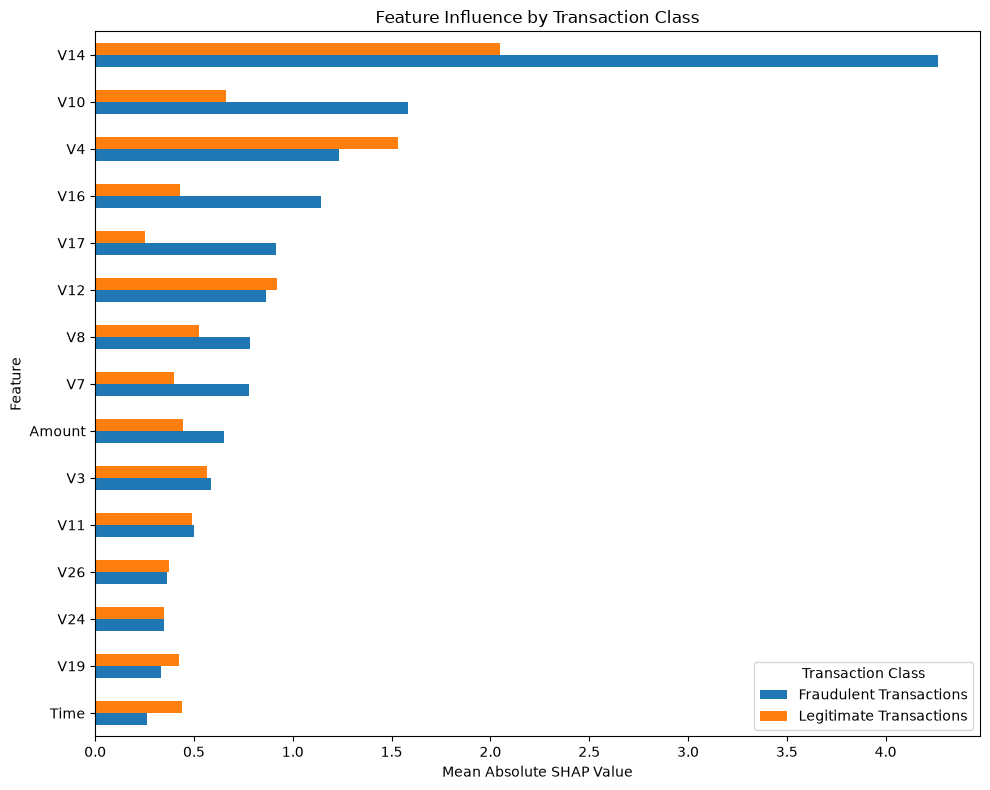

In [3]:
top_comparison = class_comparison.head(15).sort_values("Fraudulent Transactions")

top_comparison.plot(
    x="Feature",
    y=["Fraudulent Transactions", "Legitimate Transactions"],
    kind="barh",
    figsize=(10, 8),
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title("Feature Influence by Transaction Class")
plt.legend(title="Transaction Class")
plt.tight_layout()

plt.savefig(
    REPORTS_PATH / "shap_class_comparison.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

### Interpretation

The comparison shows that the model uses different feature patterns when evaluating fraudulent and legitimate transactions.

V14 is the most influential feature for both classes, although its average contribution is considerably larger for fraudulent transactions. V10, V16, V17, V8, and V7 also have stronger influence among fraudulent transactions, suggesting that these features help the model distinguish suspicious transaction patterns.

V4 and V12 have substantial influence for both transaction classes. In contrast, Time and V19 show slightly greater average influence among legitimate transactions in the sampled data.

These results should be interpreted as model behavior rather than direct causal relationships. The features describe patterns used by the model to separate the two classes, but they do not independently explain why a transaction is fraudulent.

## SHAP Dependence Analysis

V14 is the most influential feature in the model. The dependence plot below examines how V14 values relate to their SHAP contributions across the sampled transactions.

The vertical position represents the feature's contribution to the model output. Positive values increase the fraud score, while negative values decrease it.

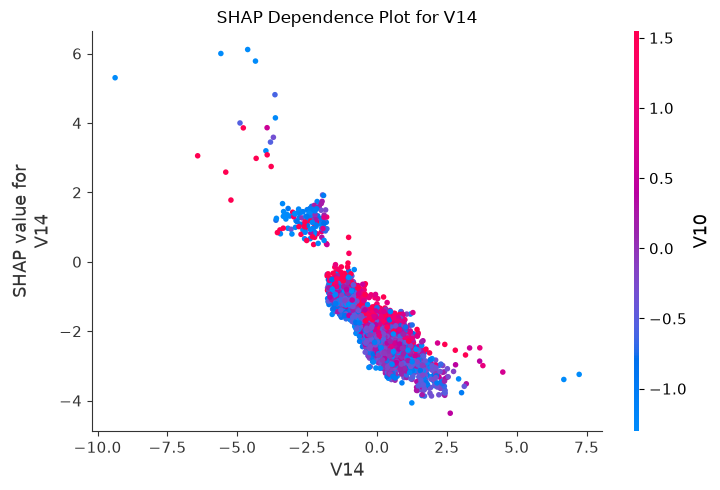

In [5]:
shap.dependence_plot(
    "V14",
    shap_values,
    X_sample,
    interaction_index="auto",
    show=False,
)

plt.title("SHAP Dependence Plot for V14")
plt.tight_layout()

plt.savefig(
    REPORTS_PATH / "shap_dependence_v14.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

### Interpretation

The dependence plot shows that the effect of V14 on the model output is nonlinear. Different V14 values can either increase or decrease the fraud score, depending on their position in the feature distribution.

Most observations with moderate V14 values produce negative SHAP contributions, which lowers the predicted fraud score. However, several observations with lower V14 values produce strongly positive contributions, indicating that these values are associated with higher fraud scores for particular transactions.

The color scale represents V10, which suggests an interaction between V14 and V10. This means that the contribution of V14 may vary depending on the value of V10. The plot demonstrates why individual feature effects should be interpreted in the context of the full model rather than in isolation.

These patterns describe the behavior learned by the model and should not be interpreted as causal relationships.

## SHAP Dependence Analysis for V4

V4 is one of the most influential features in the model. This dependence plot examines how different V4 values affect the model's fraud score and whether its effect changes in combination with another feature.

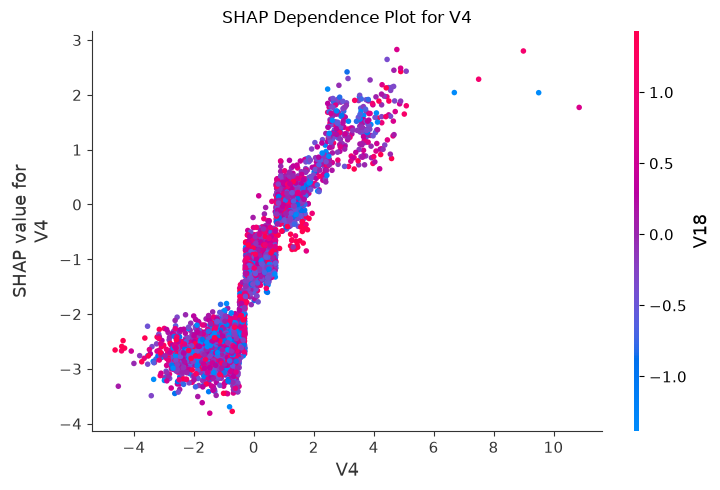

In [6]:
shap.dependence_plot(
    "V4",
    shap_values,
    X_sample,
    interaction_index="auto",
    show=False,
)

plt.title("SHAP Dependence Plot for V4")
plt.tight_layout()

plt.savefig(
    REPORTS_PATH / "shap_dependence_v4.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

### Interpretation

Higher V4 values generally increase the model's fraud score, while lower values reduce it. The nonlinear pattern shows that V4's effect varies across transactions.

The color scale suggests that V18 may interact with V4. These results describe model behavior, not causation.

## Conclusion

SHAP analysis shows that V14 and V4 are the most influential features. Their effects vary across transactions and may interact with other features.

The model provides useful explanations, but SHAP values describe model behavior rather than causal reasons for fraud.